In [1]:
import pandas as pd
import matplotlib.pyplot as plt

csv_path = "../results/robustness/different_cluster_number_repeat_metrics_melanoma.csv"
df = pd.read_csv(csv_path)

method_order = [
    'Seurat', 'MultiVI', 'MOFA+', 'GraphST', 'COSMOS',
    'PRAGA', 'MISO', 'STAGATE', 'SpatialGlue', 'SpaGenFuse',
]
metric_cols = [
    'Acc', 'V-measure', 'Homogeneity', 'Completeness',
    'NMI', 'AMI', 'FMI', 'ARI',
]

df['Method'] = pd.Categorical(df['Method'], categories=method_order, ordered=True)
df_cluster_metrics = (
    df.groupby(['Method', 'Embedding', 'n_clusters'], observed=True, sort=False)[metric_cols]
    .mean()
    .reset_index()
    .sort_values(['Method', 'n_clusters'])
)


ERROR:tornado.general:Uncaught exception in ZMQStream callback
Traceback (most recent call last):
  File "/home/yuanyongtao/.conda/envs/SpaGenFuse/lib/python3.9/site-packages/traitlets/traitlets.py", line 651, in get
    value = obj._trait_values[self.name]
KeyError: '_control_lock'

During handling of the above exception, another exception occurred:

Traceback (most recent call last):
  File "/home/yuanyongtao/.conda/envs/SpaGenFuse/lib/python3.9/site-packages/zmq/eventloop/zmqstream.py", line 565, in _log_error
    f.result()
  File "/home/yuanyongtao/.conda/envs/SpaGenFuse/lib/python3.9/site-packages/ipykernel/kernelbase.py", line 301, in dispatch_control
    async with self._control_lock:
  File "/home/yuanyongtao/.conda/envs/SpaGenFuse/lib/python3.9/site-packages/traitlets/traitlets.py", line 706, in __get__
    return self.get(obj, cls)  # type:ignore[return-value]
  File "/home/yuanyongtao/.conda/envs/SpaGenFuse/lib/python3.9/site-packages/traitlets/traitlets.py", line 668, in g

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

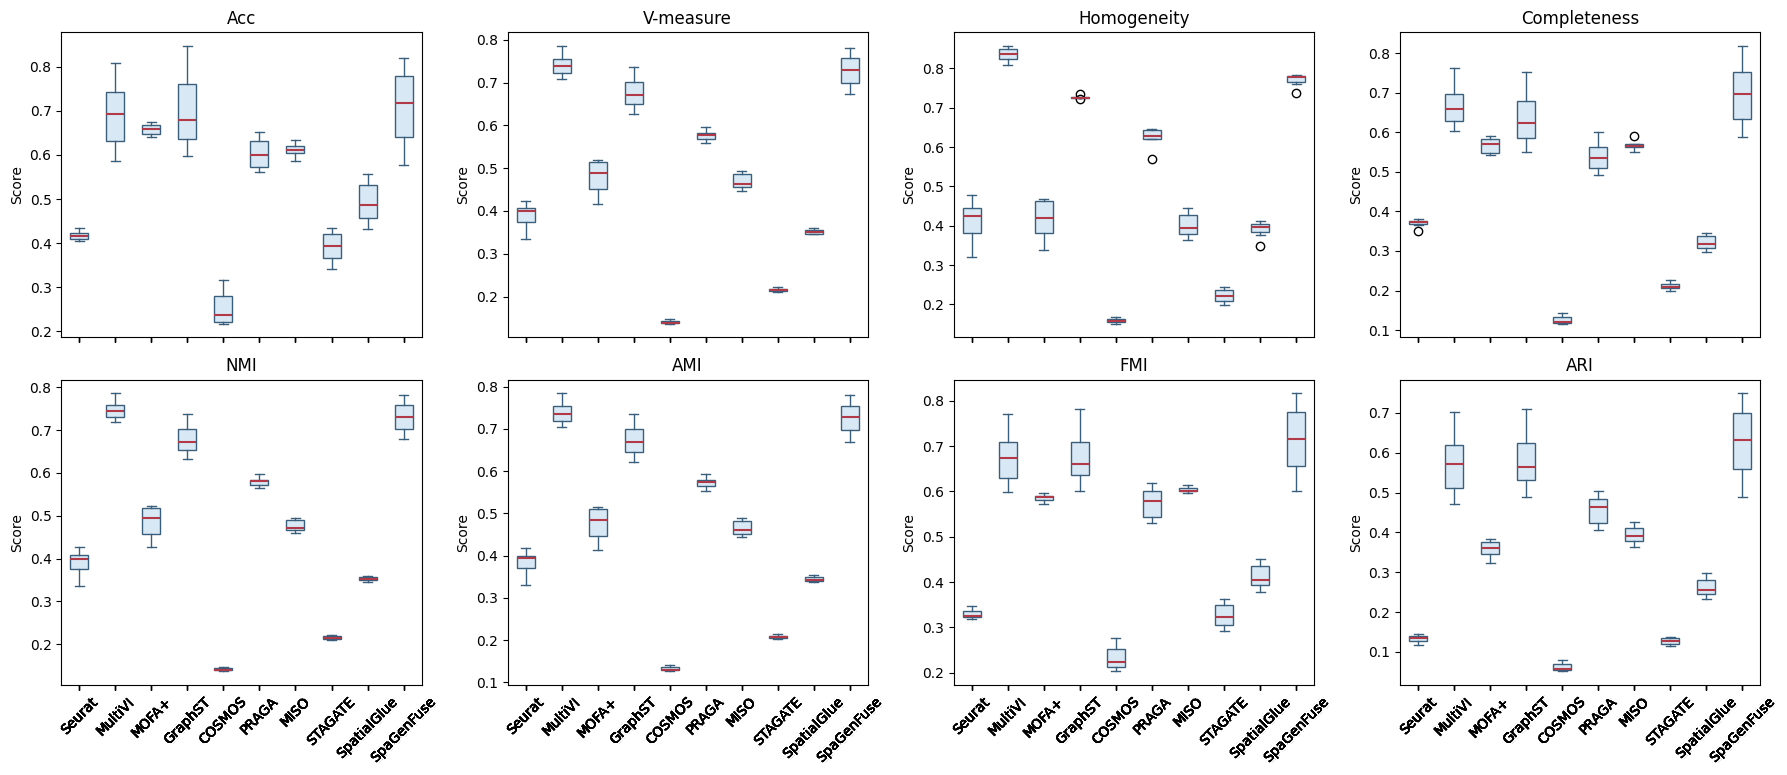

In [2]:
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 10
fig, axes = plt.subplots(2, 4, figsize=(18, 8), sharex=True)
for ax, metric in zip(axes.flatten(), metric_cols):
    df_cluster_metrics.boxplot(
        column=metric,
        by='Method',
        ax=ax,
        grid=False,
        rot=45,
        patch_artist=True,
        boxprops={'facecolor': '#D9E8F5', 'edgecolor': '#3A5F7D'},
        medianprops={'color': '#B23A48', 'linewidth': 1.5},
        whiskerprops={'color': '#3A5F7D'},
        capprops={'color': '#3A5F7D'},
    )
    ax.set_title(metric)
    ax.set_xlabel('')
    ax.set_ylabel('Score')
fig.suptitle('')
plt.tight_layout()
plt.show()
